Test model performance on different train-test splits by iteratively adjusting data distributions, evaluating shifts in accuracy, and ensuring stability across multiple randomized and stratified splits.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target]).copy()

X = df[features]
y = df[target].astype(int)

def create_model():
    return make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            random_state=42
        )
    )

print("Dataset shape:", df.shape)

Dataset shape: (79, 19)


In [2]:
results = []

for split_type in ["random", "stratified"]:
    for seed in range(10):
        stratify = y if split_type == "stratified" else None

        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=0.2,
            random_state=seed,
            stratify=stratify
        )

        model = create_model()
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        results.append({
            "Split Type": split_type,
            "Seed": seed,
            "Accuracy": accuracy_score(y_test, predictions),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Test Size": len(y_test),
            "Positive Rate": y_test.mean()
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

Split Type  Seed  Accuracy  F1 Score  Test Size  Positive Rate
    random     0    0.8125    0.8889         16         0.7500
    random     1    0.8125    0.8696         16         0.6875
    random     2    0.9375    0.9677         16         0.9375
    random     3    0.8125    0.8800         16         0.7500
    random     4    0.8750    0.9000         16         0.6250
    random     5    0.7500    0.8333         16         0.6875
    random     6    0.7500    0.8571         16         0.8750
    random     7    0.7500    0.8571         16         0.7500
    random     8    0.8125    0.8800         16         0.7500
    random     9    0.6875    0.8000         16         0.8125
stratified     0    0.8125    0.8571         16         0.7500
stratified     1    0.8125    0.8800         16         0.7500
stratified     2    0.6250    0.7500         16         0.7500
stratified     3    0.8125    0.8889         16         0.7500
stratified     4    0.8125    0.8800         16        

In [3]:
stability = results_df.groupby("Split Type").agg(
    Mean_Accuracy=("Accuracy", "mean"),
    Std_Accuracy=("Accuracy", "std"),
    Min_Accuracy=("Accuracy", "min"),
    Max_Accuracy=("Accuracy", "max"),
    Mean_F1=("F1 Score", "mean"),
    Std_F1=("F1 Score", "std")
)

print(stability.round(4))

            Mean_Accuracy  Std_Accuracy  Min_Accuracy  Max_Accuracy  Mean_F1  \
Split Type                                                                     
random             0.8000        0.0710        0.6875        0.9375   0.8734   
stratified         0.8062        0.0748        0.6250        0.9375   0.8763   

            Std_F1  
Split Type          
random      0.0441  
stratified  0.0516  


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = create_model()
model.fit(X_train, y_train)

shift_results = []
stds = X_train.std().replace(0, 1)

for shift in [0, 0.1, 0.2, 0.3, 0.5, 1.0]:
    shifted_X = X_test.copy()

    shifted_X[features] = (
        shifted_X[features] + shift * stds[features]
    )

    predictions = model.predict(shifted_X)

    shift_results.append({
        "Shift (std units)": shift,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

shift_df = pd.DataFrame(shift_results)
print(shift_df.round(4).to_string(index=False))

 Shift (std units)  Accuracy  F1 Score
               0.0    0.7500    0.8462
               0.1    0.6875    0.8148
               0.2    0.6875    0.8148
               0.3    0.6875    0.8148
               0.5    0.7500    0.8571
               1.0    0.7500    0.8571


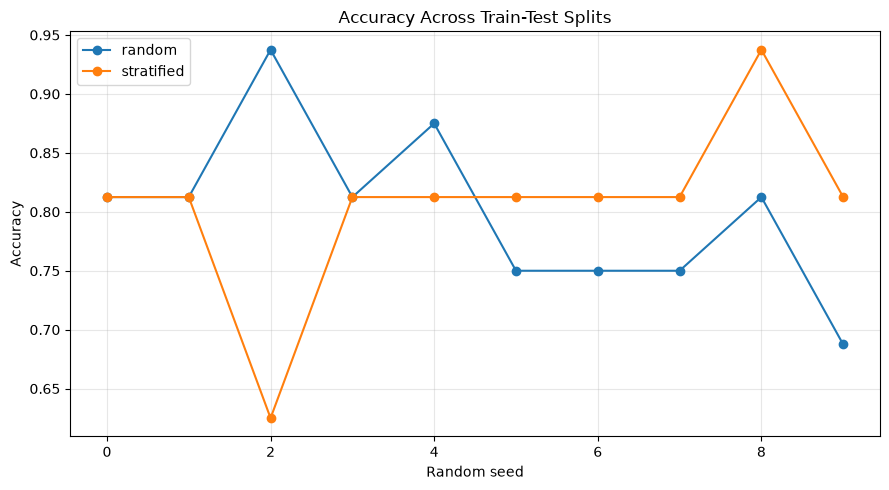

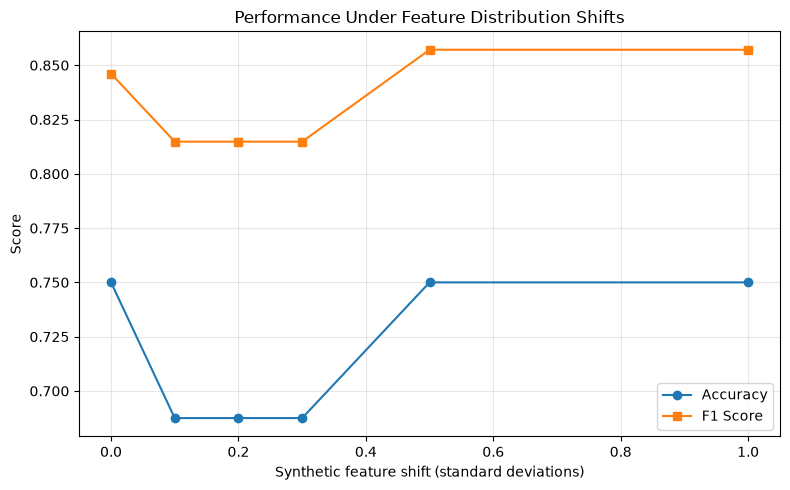

In [5]:
plt.figure(figsize=(9, 5))

for split_type, group in results_df.groupby("Split Type"):
    plt.plot(
        group["Seed"], group["Accuracy"],
        marker="o", label=split_type
    )

plt.xlabel("Random seed")
plt.ylabel("Accuracy")
plt.title("Accuracy Across Train-Test Splits")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    shift_df["Shift (std units)"],
    shift_df["Accuracy"],
    marker="o",
    label="Accuracy"
)
plt.plot(
    shift_df["Shift (std units)"],
    shift_df["F1 Score"],
    marker="s",
    label="F1 Score"
)

plt.xlabel("Synthetic feature shift (standard deviations)")
plt.ylabel("Score")
plt.title("Performance Under Feature Distribution Shifts")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
print("Split Stability")
print(stability.round(4))

print("\nDistribution Shift Results")
print(shift_df.round(4))

print("\nBaseline accuracy:", round(shift_df.iloc[0]["Accuracy"], 4))
print("Accuracy after largest shift:", round(shift_df.iloc[-1]["Accuracy"], 4))
print(
    "Accuracy change:",
    round(
        shift_df.iloc[-1]["Accuracy"] - shift_df.iloc[0]["Accuracy"],
        4
    )
)

Split Stability
            Mean_Accuracy  Std_Accuracy  Min_Accuracy  Max_Accuracy  Mean_F1  \
Split Type                                                                     
random             0.8000        0.0710        0.6875        0.9375   0.8734   
stratified         0.8062        0.0748        0.6250        0.9375   0.8763   

            Std_F1  
Split Type          
random      0.0441  
stratified  0.0516  

Distribution Shift Results
   Shift (std units)  Accuracy  F1 Score
0                0.0    0.7500    0.8462
1                0.1    0.6875    0.8148
2                0.2    0.6875    0.8148
3                0.3    0.6875    0.8148
4                0.5    0.7500    0.8571
5                1.0    0.7500    0.8571

Baseline accuracy: 0.75
Accuracy after largest shift: 0.75
Accuracy change: 0.0
